# 🇧🇯 BENIN Fongbe Tonal ASR Challenge — Pôle 1 : Data Engineering (Personne 1)

**Rôle :** Personne 1 — Data Engineering (Préparation, Audit et Compréhension des Données)  
**Livrable final :** Dataset propre, sans fuite de locuteur, et documenté (`train_manifest.jsonl`, `val_manifest.jsonl`, `test_manifest.jsonl`, `dataset_metadata_report.json`), prêt à être transmis aux pôles ASR (Personne 2) et NLP (Personne 3).

### Sommaire de vos 6 missions traitées dans ce Notebook :
1. **Traitement & Audit du fichier officiel `SampleSubmission.csv`** (9 407 échantillons, détection des 31 IDs absents, création du manifest de test).
2. **Exploration des fichiers audio** (formats, fréquences d'échantillonnage, durées, énergie RMS, ratio de silence, saturation).
3. **Vérification de la qualité des annotations** (séparation des 3 sources : *multi-locuteurs validés*, *lectures bibliques*, *tons incertains*).
4. **Détection et filtrage des données manquantes ou problématiques** (audios trop courts, silencieux, transcriptions vides, glyphes corrompus).
5. **Analyse des caractéristiques linguistiques du Fongbé** (caractères spéciaux `ɖ, ɔ, ɛ`, digraphes `gb, kp, xw...`, voyelles nasales, distribution des tons).
6. **Préparation finale des jeux d'entraînement, de validation (Speaker-Disjoint) et export des métadonnées**.


In [1]:
import sys
import json
import wave
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
print(f"Racine du projet configurée : {PROJECT_ROOT}")

Racine du projet configurée : /home/hilarie/Hackathon_1


---
## Mission 1 — Traitement et Audit de `SampleSubmission.csv`

Nous analysons le fichier `SampleSubmission.csv` fourni par les organisateurs afin d'identifier la structure exacte attendue pour le jeu de test et détecter d'éventuels sauts de numérotation dans les identifiants `test_XXXXXX`.

In [2]:
from src.data.submission_parser import audit_sample_submission
from src.data.dataset import build_test_manifest_from_submission

sample_sub_path = PROJECT_ROOT / "data" / "raw" / "SampleSubmission.csv"
sub_audit = audit_sample_submission(sample_sub_path)

print("=== DIAGNOSTIC COMPLET DE SampleSubmission.csv ===")
print(f"Colonnes                   : {sub_audit['columns']}")
print(f"Nombre exact de lignes     : {sub_audit['total_rows']:,}")
print(f"Identifiants uniques       : {sub_audit['unique_ids']:,} (Doublons : {sub_audit['duplicate_ids']})")
print(f"Plage d'identifiants       : {sub_audit['min_id']} -> {sub_audit['max_id']} (étendue = {sub_audit['sequence_span']})")
print(f"Ordre strictement croissant: {sub_audit['is_strictly_monotonic']}")
print(f"IDs sautés dans la séquence: {sub_audit['missing_sequence_count']} identifiants absents !")
print(f"Sauts consécutifs détectés : {sub_audit['consecutive_gap_groups']}")
print("\nListe exacte des 31 IDs absents (à ne jamais générer dans une boucle naïve) :")
print(sub_audit["missing_sequence_ids"])

sample_df = pd.read_csv(sample_sub_path, dtype=str).fillna("")
display(sample_df.head(10))

=== DIAGNOSTIC COMPLET DE SampleSubmission.csv ===
Colonnes                   : ['ID', 'Target']
Nombre exact de lignes     : 9,407
Identifiants uniques       : 9,407 (Doublons : 0)
Plage d'identifiants       : test_000001 -> test_009438 (étendue = 9438)
Ordre strictement croissant: True
IDs sautés dans la séquence: 31 identifiants absents !
Sauts consécutifs détectés : [['test_004571', 'test_004572', 'test_004573']]

Liste exacte des 31 IDs absents (à ne jamais générer dans une boucle naïve) :
['test_000186', 'test_000638', 'test_000868', 'test_000884', 'test_001213', 'test_001334', 'test_001445', 'test_002749', 'test_002947', 'test_003086', 'test_003638', 'test_003956', 'test_004549', 'test_004571', 'test_004572', 'test_004573', 'test_005142', 'test_005217', 'test_005949', 'test_006330', 'test_006456', 'test_006732', 'test_006940', 'test_007155', 'test_007251', 'test_007335', 'test_007435', 'test_007723', 'test_008324', 'test_009185', 'test_009353']


,ID,Target
0,test_000001,
1,test_000002,
2,test_000003,
3,test_000004,
4,test_000005,
5,test_000006,
6,test_000007,
7,test_000008,
8,test_000009,
9,test_000010,


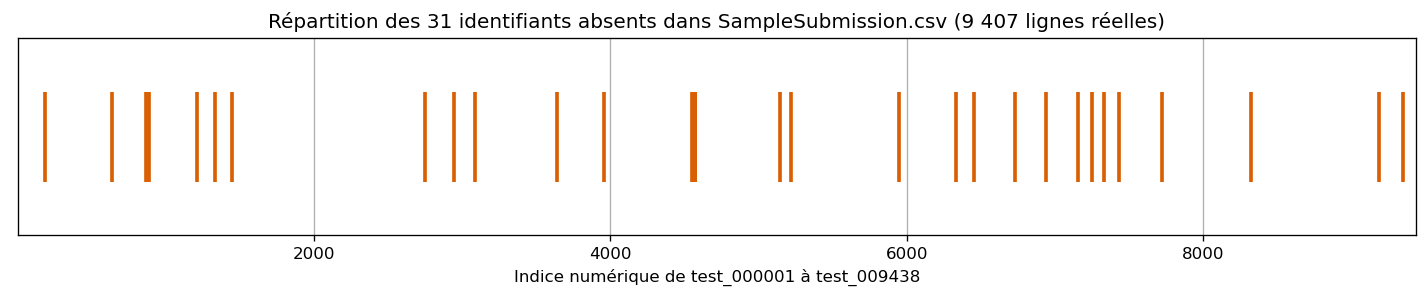

In [3]:
# Visualisation de la position des 31 identifiants absents entre test_000001 et test_009438
missing_nums = [int(x.split("_")[1]) for x in sub_audit["missing_sequence_ids"]]

fig, ax = plt.subplots(figsize=(12, 2.6))
ax.eventplot(missing_nums, orientation="horizontal", colors="#d95f02", linewidths=2.2)
ax.set_xlim(1, 9438)
ax.set_yticks([])
ax.set_xlabel("Indice numérique de test_000001 à test_009438")
ax.set_title("Répartition des 31 identifiants absents dans SampleSubmission.csv (9 407 lignes réelles)")
plt.tight_layout()
plt.show()

---
## Mission 2 — Exploration Audio : Formats, Durées et Caractéristiques Acoustiques

Tant que l'archive complète de 350 heures (`Train.csv` + dossier `wav`) n'est pas encore déposée dans `data/raw/`, le pipeline charge automatiquement un **jeu d'essai réaliste Fongbé** contenant à la fois des enregistrements valides et des anomalies types (audio trop court, silence pur, texte bruité) afin de démontrer toutes les étapes de contrôle qualité. Dès que `data/raw/Train.csv` est présent, ce même code traite directement les 350 heures !

In [4]:
from src.data.synthetic_data import generate_demo_dataset
from src.data.audit import audit_dataset_records

real_train_csv = PROJECT_ROOT / "data" / "raw" / "Train.csv"
if real_train_csv.exists():
    raw_train_df = pd.read_csv(real_train_csv)
    test_audio_dir = PROJECT_ROOT / "data" / "raw" / "test"
    print("Chargement du dataset réel :", real_train_csv)
else:
    demo_dir = PROJECT_ROOT / "data" / "processed" / "pole1_notebook_demo"
    demo_info = generate_demo_dataset(demo_dir, test_ids=sample_df["ID"].head(5).tolist())
    raw_train_df = pd.read_csv(demo_info["train_csv"])
    test_audio_dir = Path(demo_info["test_audio_dir"])
    print(f"Jeu d'exploration généré ({len(raw_train_df)} enregistrements WAV 16 kHz Mono PCM 16-bit)")

audit_report = audit_dataset_records(raw_train_df.to_dict("records"))
audit_df = pd.DataFrame(audit_report["records"])

print("\nStatistiques globales des durées audio (en secondes) :", audit_report["duration_stats_sec"])
display(audit_df[["ID", "samplerate", "channels", "bit_depth", "duration", "rms_energy", "silence_ratio", "Target"]].head(10))

Jeu d'exploration généré (15 enregistrements WAV 16 kHz Mono PCM 16-bit)

Statistiques globales des durées audio (en secondes) : {'min': 0.2, 'mean': 1.668, 'median': 1.713, 'max': 4.769}


,ID,samplerate,channels,bit_depth,duration,rms_energy,silence_ratio,Target
0,train_000001,16000,1,16,1.1550,0.24403,0.3002,Un nɔ́ ɖu nǔ
1,train_000002,16000,1,16,0.8066,0.23591,0.3269,A fɔ́n à
2,train_000003,16000,1,16,1.1392,0.24386,0.3011,É nyɔ́ ɖésú
3,train_000004,16000,1,16,1.7134,0.24757,0.2849,Mǐ ná yì kutɔ́nu
4,train_000005,16000,1,16,1.7663,0.24557,0.2846,Nɔví ce wá xwé gbe
5,train_000006,16000,1,16,1.1309,0.24299,0.3029,Kú ɖó azɔ̌
6,train_000007,16000,1,16,4.7694,0.24659,0.2776,Mawu jíɖótó ɔ́ bló jǐnukúnsin kpódó ayikúngban kpó
7,train_000008,16000,1,16,2.5337,0.24560,0.2792,12:4 Xó ɔ́ ko ɖè sín bǐbɛ́mɛ ε
8,train_000009,16000,1,16,2.3166,0.24698,0.2778,Gbɛtɔ́ lɛ́ɛ bǐ wɛ nyí nɔví
9,train_000010,16000,1,16,2.2349,0.24509,0.2830,Un jló ná kplɔ́n fɔngbe


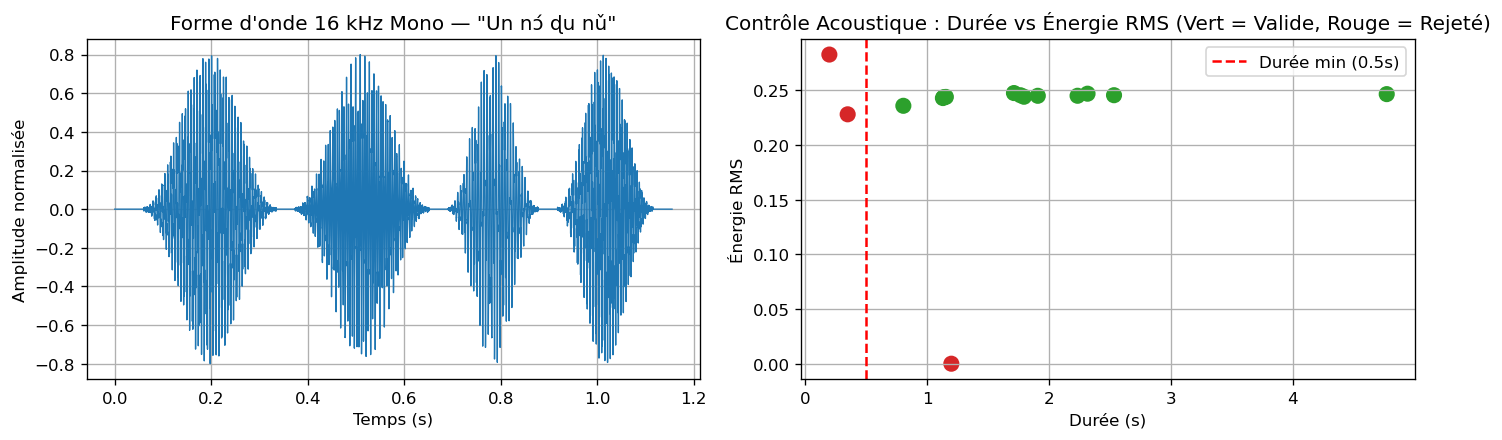

In [5]:
# Visualisation d'un enregistrement audio Fongbé et de la distribution des durées / énergies RMS
first_wav = Path(audit_df.iloc[0]["audio_filepath"])
with wave.open(str(first_wav), "rb") as wf:
    sr = wf.getframerate()
    sig = np.frombuffer(wf.readframes(wf.getnframes()), dtype=np.int16).astype(np.float32) / 32768.0

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(np.arange(len(sig)) / sr, sig, color="#1f77b4", linewidth=0.8)
axes[0].set_title(f"Forme d'onde 16 kHz Mono — \"{audit_df.iloc[0]['Target']}\"")
axes[0].set_xlabel("Temps (s)")
axes[0].set_ylabel("Amplitude normalisée")

axes[1].scatter(audit_df["duration"], audit_df["rms_energy"], c=audit_df["is_clean_for_training"].map({True: "#2ca02c", False: "#d62728"}), s=75)
axes[1].axvline(0.5, color="red", linestyle="--", label="Durée min (0.5s)")
axes[1].set_title("Contrôle Acoustique : Durée vs Énergie RMS (Vert = Valide, Rouge = Rejeté)")
axes[1].set_xlabel("Durée (s)")
axes[1].set_ylabel("Énergie RMS")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Missions 3 & 4 — Qualité des Annotations et Détection des Données Problématiques

Nous classons chaque échantillon dans l'une des **3 catégories de qualité** décrites dans l'énoncé (*multi-locuteurs validés*, *lectures bibliques*, *annotations tonales incertaines*) et nous isolons toutes les anomalies audio et textuelles.

In [6]:
from src.data.submission_parser import categorize_subset_quality

audit_df["quality_tier"] = [categorize_subset_quality(r) for r in audit_df.to_dict("records")]

print("=== BILAN DES ANOMALIES DÉTECTÉES ===")
for k, v in audit_report["anomalies_summary"].items():
    print(f"  - {k:30s} : {v}")

print(f"\nEnregistrements retenus : {audit_report['clean_records_count']} / {audit_report['total_records_audited']}")
print("Enregistrements présentant au moins un signalement (anomalie bloquante ou texte à nettoyer) :")
flagged_df = audit_df[audit_df["anomaly_flags"].map(len) > 0][["ID", "duration", "rms_energy", "Target", "anomaly_flags", "is_clean_for_training"]]
display(flagged_df)

=== BILAN DES ANOMALIES DÉTECTÉES ===
  - missing_or_corrupted_audio     : 0
  - too_short_audio                : 2
  - too_long_audio                 : 0
  - near_silent_audio              : 1
  - clipped_audio                  : 0
  - empty_transcription            : 0
  - unexpected_chars_in_text       : 1
  - abnormal_speech_rate           : 0
  - needs_audio_standardization    : 0

Enregistrements retenus : 12 / 15
Enregistrements présentant au moins un signalement (anomalie bloquante ou texte à nettoyer) :


,ID,duration,rms_energy,Target,anomaly_flags,is_clean_for_training
7,train_000008,2.5337,0.24560,12:4 Xó ɔ́ ko ɖè sín bǐbɛ́mɛ ε,[unexpected_chars:124:ε],True
12,train_000013,0.2000,0.28278,Ó,[too_short],False
13,train_000014,1.2000,0.00000,Un nɔ́ se fɔngbe,[near_silent],False
14,train_000015,0.3502,0.22812,nan,[too_short],False


---
## Mission 5 — Analyse des Caractéristiques Linguistiques du Fongbé

Nous analysons sur les transcriptions propres :
- La **distribution des marques tonales** (Ton Haut `´`, Ton Montant `ˇ`, Ton Bas `` ` ``, Ton Descendant `ˆ`, Ton Moyen non marqué).
- Les **caractères spéciaux béninois** (`ɖ`, `ɔ`, `ɛ`), les **digraphes consonantiques** (`gb`, `kp`, `hw`, `xw`, `ny`) et les **voyelles nasales** (`an`, `ɛn`, `in`, `ɔn`, `un`).

=== RAPPORT LINGUISTIQUE FONGBÉ ===
{
  "total_sentences": 12,
  "total_words": 57,
  "avg_words_per_sentence": 4.75,
  "avg_chars_per_word": 3.09,
  "unique_nfd_symbols": 29,
  "special_fongbe_chars": {
    "ɔ": 13,
    "ɖ": 6,
    "ɛ": 9
  },
  "digraph_frequencies": {
    "ny": 2,
    "gb": 5,
    "xw": 1,
    "kp": 3
  },
  "nasal_vowel_frequencies": {
    "un": 4,
    "ɔn": 3,
    "an": 1,
    "in": 2
  },
  "tone_distribution": {
    "Ton Haut (´)": 34,
    "Ton Montant (ˇ)": 6,
    "Ton Bas (`)": 3,
    "Ton Moyen / Non-marqué": 40
  }
}


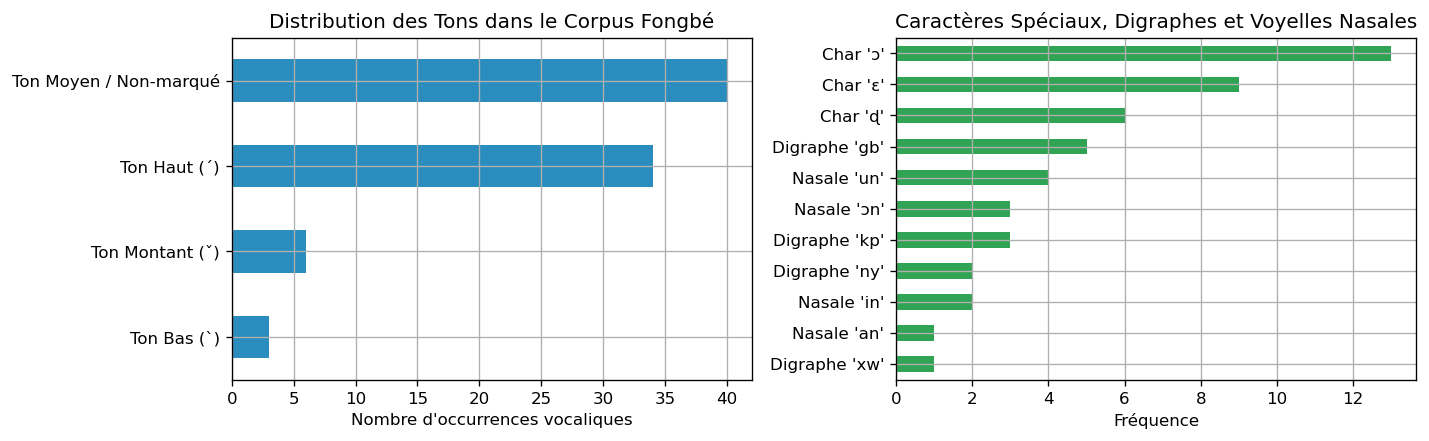

In [7]:
from src.data.fongbe_phonetics import analyze_fongbe_linguistics
from src.data.dataset import clean_text_for_manifest

clean_df = audit_df[audit_df["is_clean_for_training"]].copy()
clean_df["text_clean"] = clean_df["Target"].map(clean_text_for_manifest)

ling_stats = analyze_fongbe_linguistics(clean_df["text_clean"].tolist())
print("=== RAPPORT LINGUISTIQUE FONGBÉ ===")
print(json.dumps(ling_stats, ensure_ascii=False, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
tones_s = pd.Series(ling_stats["tone_distribution"]).sort_values(ascending=True)
tones_s.plot(kind="barh", ax=axes[0], color="#2b8cbe")
axes[0].set_title("Distribution des Tons dans le Corpus Fongbé")
axes[0].set_xlabel("Nombre d'occurrences vocaliques")

spec_items = {**{f"Char '{k}'": v for k, v in ling_stats["special_fongbe_chars"].items()},
              **{f"Digraphe '{k}'": v for k, v in ling_stats["digraph_frequencies"].items()},
              **{f"Nasale '{k}'": v for k, v in ling_stats["nasal_vowel_frequencies"].items()}}
pd.Series(spec_items).sort_values(ascending=True).plot(kind="barh", ax=axes[1], color="#31a354")
axes[1].set_title("Caractères Spéciaux, Digraphes et Voyelles Nasales")
axes[1].set_xlabel("Fréquence")

plt.tight_layout()
plt.show()

---
## Mission 6 — Préparation Finale Train / Validation (Speaker-Disjoint) & Export des Livrables

Nous générons enfin les **4 livrables officiels de la Personne 1** dans `data/manifests/`, accompagnés d'une démonstration de *Data Augmentation* respectueuse des tons (ajout de bruit contrôlé sans déformation de la hauteur tonale $F_0$).

In [8]:
from src.data.dataset import create_manifest_entry, split_by_speaker, save_manifest
from src.data.augmentation import add_gaussian_noise

manifest_entries = [
    create_manifest_entry(
        audio_path=r["audio_filepath"],
        raw_transcript=r["Target"],
        duration=r["duration"],
        speaker_id=r["speaker_id"],
        sample_id=r["ID"],
        quality_tier=r["quality_tier"],
    )
    for r in clean_df.to_dict("records")
]

train_entries, val_entries = split_by_speaker(manifest_entries, val_ratio=0.25, seed=42)

manifests_dir = PROJECT_ROOT / "data" / "manifests"
train_manifest_path = manifests_dir / "train_manifest.jsonl"
val_manifest_path = manifests_dir / "val_manifest.jsonl"
test_manifest_path = manifests_dir / "test_manifest.jsonl"
report_json_path = manifests_dir / "dataset_metadata_report.json"

save_manifest(train_entries, train_manifest_path)
save_manifest(val_entries, val_manifest_path)
test_entries = build_test_manifest_from_submission(sample_sub_path, test_audio_dir, test_manifest_path)

metadata_summary = {
    "pole": "Personne 1 — Data Engineering",
    "sample_submission_audit": sub_audit,
    "training_audit": {k: v for k, v in audit_report.items() if k != "records"},
    "fongbe_linguistics": ling_stats,
    "manifests_generated": {
        "train_manifest": str(train_manifest_path),
        "train_samples": len(train_entries),
        "train_speakers": sorted({r["speaker_id"] for r in train_entries}),
        "val_manifest": str(val_manifest_path),
        "val_samples": len(val_entries),
        "val_speakers": sorted({r["speaker_id"] for r in val_entries}),
        "speaker_leakage_count": len({r["speaker_id"] for r in train_entries} & {r["speaker_id"] for r in val_entries}),
        "test_manifest": str(test_manifest_path),
        "test_samples": len(test_entries),
    }
}
report_json_path.write_text(json.dumps(metadata_summary, ensure_ascii=False, indent=2), encoding="utf-8")

print("=== LIVRABLES FINAUX PERSONNE 1 GÉNÉRÉS AVEC SUCCÈS ===")
print(json.dumps(metadata_summary["manifests_generated"], ensure_ascii=False, indent=2))
print("\nAperçu des entrées standardisées prêtes pour l'entraînement (train_manifest.jsonl) :")
display(pd.DataFrame(train_entries))

=== LIVRABLES FINAUX PERSONNE 1 GÉNÉRÉS AVEC SUCCÈS ===
{
  "train_manifest": "/home/hilarie/Hackathon_1/data/manifests/train_manifest.jsonl",
  "train_samples": 8,
  "train_speakers": [
    "spk_01",
    "spk_03",
    "spk_05",
    "spk_06"
  ],
  "val_manifest": "/home/hilarie/Hackathon_1/data/manifests/val_manifest.jsonl",
  "val_samples": 4,
  "val_speakers": [
    "spk_02",
    "spk_04"
  ],
  "speaker_leakage_count": 0,
  "test_manifest": "/home/hilarie/Hackathon_1/data/manifests/test_manifest.jsonl",
  "test_samples": 9407
}

Aperçu des entrées standardisées prêtes pour l'entraînement (train_manifest.jsonl) :


,id,audio_filepath,duration,text_raw,text_clean,text_syllabified,speaker_id,quality_tier
0,train_000001,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000001.wav,1.155,Un nɔ́ ɖu nǔ,un nɔ́ ɖu nǔ,un nɔ1 ɖu nu3,spk_01,validated_multispeaker
1,train_000002,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000002.wav,0.807,A fɔ́n à,a fɔ́n à,a fɔn1 a4,spk_01,validated_multispeaker
2,train_000005,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000005.wav,1.766,Nɔví ce wá xwé gbe,nɔví ce wá xwé gbe,nɔ vi1 ce wa1 xwe1 gbe,spk_03,validated_multispeaker
3,train_000006,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000006.wav,1.131,Kú ɖó azɔ̌,kú ɖó azɔ̌,ku1 ɖo1 a zɔ3,spk_03,validated_multispeaker
4,train_000009,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000009.wav,2.317,Gbɛtɔ́ lɛ́ɛ bǐ wɛ nyí nɔví,gbɛtɔ́ lɛ́ɛ bǐ wɛ nyí nɔví,gbɛ tɔ1 lɛɛ1 bi3 wɛ nyi1 nɔ vi1,spk_05,validated_multispeaker
5,train_000010,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000010.wav,2.235,Un jló ná kplɔ́n fɔngbe,un jló ná kplɔ́n fɔngbe,un j lo1 na1 kp lɔn1 fɔn gbe,spk_05,validated_multispeaker
6,train_000011,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000011.wav,1.909,E yi axi me egbe,e yi axi me egbe,e yi a xi me e gbe,spk_06,uncertain_tones
7,train_000012,/home/hilarie/Hackathon_1/data/processed/pole1_notebook_demo/demo_audio/train/train_000012.wav,1.796,Vi lɛ ɖo wemaxɔmɛ,vi lɛ ɖo wemaxɔmɛ,vi lɛ ɖo we ma xɔ mɛ,spk_06,uncertain_tones
